# Clasificación temática de textos en Esperanto
### Práctica de programación · Minería de Textos · 4º INF · 2026/2027

**Integrantes:** _(completar con los nombres del equipo)_

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gonvt/Mineria-de-textos/blob/main/notebooks/clasificacion_esperanto.ipynb)

En este cuaderno se construye, de principio a fin, un sistema que clasifica
textos en **Esperanto** según su temática científica:

| Clase | Categoría de Vikipedio | Qué contiene |
|---|---|---|
| `fiziko` | [Kategorio:Fiziko](https://eo.wikipedia.org/wiki/Kategorio:Fiziko) | física: mecánica, óptica, electromagnetismo... |
| `kemio` | [Kategorio:Kemio](https://eo.wikipedia.org/wiki/Kategorio:Kemio) | química: elementos, reacciones, compuestos... |
| `biologio` | [Kategorio:Biologio](https://eo.wikipedia.org/wiki/Kategorio:Biologio) | biología: células, ecología, genética... |

Las tres son ramas de las ciencias naturales, **semánticamente cercanas**
(comparten vocabulario: *energio, molekulo, ĉelo, atomo, reakcio*...), así que
el problema no es trivial.

**Índice**

0. Configuración y parámetros
1. **Fase 1 – Dataset**: descarga de Vikipedio, limpieza y división en párrafos
2. **Fase 2 – NLP**: modelo propio para Esperanto con API tipo spaCy
3. **Fase 3 – Clasificación**: vectorización TF-IDF, entrenamiento y evaluación
4. **Clasificación de páginas web** reales mediante *web scraping*
5. Conclusiones

> El código de las fases 1–3 también está organizado como librería instalable
> (`pip install git+https://github.com/gonvt/Mineria-de-textos`) con tests, en la carpeta `eonlp/`
> del repositorio. Este cuaderno es **autocontenido**: no importa esa librería,
> sino que incluye todo su código en las celdas.

## 0. Configuración y parámetros

Todos los parámetros de ejecución están en esta celda.

* `GENERAR_DATASET = False` (por defecto): se usa el dataset ya generado y
  publicado en GitHub (*ejecución asíncrona*, sección 4.1.4 del enunciado).
  Así el cuaderno tarda menos de 2 minutos.
* `GENERAR_DATASET = True`: se ejecuta el *script* de la Fase 1 y se descarga
  todo de nuevo desde el API de Vikipedio (unos 10–15 minutos, ~900 peticiones).

Si la descarga del dataset publicado falla, el cuaderno lo genera
automáticamente desde Vikipedio (y viceversa): **sobrevive al fallo de cualquiera
de las dos fuentes**.

In [1]:
# ---------------------------- PARÁMETROS ----------------------------------
GENERAR_DATASET = False        # True = volver a descargar todo desde Vikipedio
MAX_ARTICULOS_POR_CLASE = 300  # artículos por categoría (solo si se genera)
PROFUNDIDAD_SUBCATEGORIAS = 2  # niveles de subcategorías a recorrer
SEED = 42                      # semilla para que los resultados sean reproducibles

URL_DATASET = "https://raw.githubusercontent.com/gonvt/Mineria-de-textos/main/data/dataset_con_titulos.csv"   # text;class;title
URL_DATASET_CONTRATO = "https://raw.githubusercontent.com/gonvt/Mineria-de-textos/main/data/dataset.csv"      # text;class (contrato de datos)
URL_WEB_SNAPSHOT = "https://raw.githubusercontent.com/gonvt/Mineria-de-textos/main/data/web_snapshot.json"     # copia de respaldo de las webs

In [2]:
import json
import random
import re
import sys
import time
import unicodedata
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
from bs4 import BeautifulSoup

warnings.filterwarnings("ignore", category=UserWarning)
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORES = {"fiziko": "#2a78b5", "kemio": "#d9822b", "biologio": "#3a9a5b"}

print("Python      ", sys.version.split()[0])
for lib in (pd, np, sklearn, matplotlib, requests):
    print(f"{lib.__name__:<12}", lib.__version__)

Python       3.13.18
pandas       3.0.5
numpy        2.5.3
sklearn      1.9.1
matplotlib   3.11.2
requests     2.34.2


## 1. Fase 1 – Dataset

### 1.1 Fuente de datos y temáticas

Se usa el **API de MediaWiki de Vikipedio** (`eo.wikipedia.org/w/api.php`):

1. `list=categorymembers` para recorrer cada categoría **en anchura (BFS)** y sus
   subcategorías hasta 2 niveles, hasta reunir 300 artículos por clase.
2. `prop=extracts&explaintext=1` para obtener el **texto plano** de cada artículo
   (sin HTML, plantillas ni enlaces).

**Decisiones de diseño**

* **Subcategorías excluidas**: biografías (*Fizikistoj, Kemiistoj, Biologoj*),
  listas, organizaciones, premios, esbozos (*Ĝermoj*) y, sobre todo, las
  **interdisciplinares** (*Biofiziko, Biokemio, Kvantuma kemio*), que
  pertenecerían a dos clases a la vez. También *Metalurgio* / *Kemia industrio*,
  que se alejan hacia la industria y la historia.
* Un artículo que aparece en **más de una clase** se descarta (etiqueta ambigua).
* Cada artículo se divide en **párrafos**; se ignoran los títulos de sección y
  todo lo que va después de *Vidu ankaŭ, Referencoj, Notoj, Eksteraj ligiloj*...
* Limpieza: URLs, referencias `[1]`, fórmulas LaTeX, el carácter `;`
  (contrato de datos) y párrafos con menos de 15 palabras o con menos de un
  75 % de letras (tablas, listas de cifras).
* Se eliminan los párrafos duplicados (textos de plantilla repetidos).
* Las peticiones tienen **reintentos con espera** y nunca lanzan excepción:
  si una petición falla, ese artículo simplemente se queda sin texto.

In [3]:
# ===== Código de eonlp/dataset.py =====
"""Fase 1 - Construcción del dataset a partir de Vikipedio (Wikipedia en Esperanto).

Flujo:

1. ``collect_titles``: recorre una categoría de Wikipedia (y sus subcategorías
   hasta ``max_depth`` niveles, en anchura) y recoge títulos de artículos.
2. ``fetch_extract``: descarga el texto plano de cada artículo (API ``extracts``).
3. ``split_paragraphs`` + ``clean_paragraph``: divide en párrafos y limpia
   referencias, URLs, fórmulas, secciones finales ("Vidu ankaŭ", "Referencoj"...).
4. ``build_dataset``: une todo, elimina duplicados y artículos que aparecen en
   más de una clase, y devuelve un ``DataFrame`` con columnas ``text;class``.

Contrato de datos: CSV UTF-8, separador ``;``, cabecera ``text;class``,
un párrafo por fila, sin ``;`` en el texto y sin HTML/links/referencias.
"""

import re
import time

import pandas as pd

API_URL = "https://eo.wikipedia.org/w/api.php"
USER_AGENT = "MineriaDeTextos-Esperanto/1.0 (proyecto universitario; python-requests)"

# Categorías elegidas: tres ramas de las ciencias naturales (semánticamente cercanas)
CATEGORIES = {
    "fiziko": "Kategorio:Fiziko",
    "kemio": "Kategorio:Kemio",
    "biologio": "Kategorio:Biologio",
}

# Subcategorías que NO se recorren: biografías, listas, organizaciones,
# esbozos y temas mixtos (biofísica, bioquímica...) que mezclarían clases.
EXCLUDED_SUBCATEGORIES = re.compile(
    r"(istoj|ologoj|Listoj|Ĝermoj|Ŝablono|organizaĵoj|asocioj|premioj|fikcio|Magio|"
    r"Artikoloj sen|datumbazoj|socio|Biofiziko|Biokemio|Kvantuma kemio|Historio de|"
    r"Filozofio de|literaturo|kulturo|Metalurgio|industrio|inĝenierarto)",
    re.IGNORECASE,
)

# Secciones finales sin contenido temático
END_SECTIONS = re.compile(
    r"^(Vidu ankaŭ|Referencoj|Notoj|Eksteraj ligiloj|Ligiloj|Literaturo|Fontoj|"
    r"Bibliografio|Piednotoj|Rilataj artikoloj|Plia legado)\b",
    re.IGNORECASE,
)

MIN_WORDS = 15       # párrafos más cortos se descartan (títulos, pies de figura...)
MAX_WORDS = 300      # párrafos muy largos se recortan a esta longitud


# --------------------------------------------------------------------------
# Acceso al API de Wikipedia
# --------------------------------------------------------------------------
def make_session():
    import requests

    s = requests.Session()
    s.headers["User-Agent"] = USER_AGENT
    return s


def api_get(session, params, retries=4, timeout=30, pause=1.5):
    """Llamada GET al API con reintentos y espera exponencial.

    Devuelve el JSON o ``None`` si todos los intentos fallan (no lanza excepción:
    el cuaderno debe sobrevivir a fallos de red).
    """
    params = {"format": "json", "formatversion": "2", **params}
    for attempt in range(retries):
        try:
            r = session.get(API_URL, params=params, timeout=timeout)
            if r.status_code == 200:
                return r.json()
        except Exception:  # noqa: BLE001 - cualquier fallo de red se reintenta
            pass
        time.sleep(pause * (attempt + 1))
    return None


def category_members(session, category, member_type):
    """Lista los títulos de una categoría (``member_type`` = ``page`` o ``subcat``)."""
    titles, cont = [], {}
    while True:
        params = {
            "action": "query", "list": "categorymembers", "cmtitle": category,
            "cmtype": member_type, "cmnamespace": "0" if member_type == "page" else "14",
            "cmlimit": "500", **cont,
        }
        data = api_get(session, params)
        if not data:
            break
        titles += [m["title"] for m in data["query"]["categorymembers"]]
        if "continue" in data:
            cont = {"cmcontinue": data["continue"]["cmcontinue"]}
        else:
            break
    return titles


def collect_titles(session, root, max_articles=300, max_depth=2):
    """Recorrido en anchura (BFS) de la categoría ``root`` y sus subcategorías."""
    seen_cats = {root}
    queue = [(root, 0)]
    articles = []
    while queue and len(articles) < max_articles:
        cat, depth = queue.pop(0)
        for title in category_members(session, cat, "page"):
            if title.startswith("Listo"):
                continue
            if title not in articles:
                articles.append(title)
            if len(articles) >= max_articles:
                break
        if depth < max_depth:
            for sub in category_members(session, cat, "subcat"):
                if sub not in seen_cats and not EXCLUDED_SUBCATEGORIES.search(sub):
                    seen_cats.add(sub)
                    queue.append((sub, depth + 1))
    return articles


def fetch_extract(session, title):
    """Texto plano completo de un artículo (sin HTML gracias a ``explaintext``)."""
    data = api_get(session, {
        "action": "query", "prop": "extracts", "explaintext": "1",
        "exsectionformat": "wiki", "redirects": "1", "titles": title,
    })
    try:
        return data["query"]["pages"][0].get("extract", "") or ""
    except (TypeError, KeyError, IndexError):
        return ""


def download_articles(categories=None, max_articles=300, max_depth=2, delay=0.1, verbose=True):
    """Descarga los artículos de cada clase: ``{clase: [{title, text}, ...]}``."""
    categories = categories or CATEGORIES
    session = make_session()
    raw = {}
    for label, cat in categories.items():
        titles = collect_titles(session, cat, max_articles, max_depth)
        raw[label] = []
        for i, title in enumerate(titles):
            raw[label].append({"title": title, "text": fetch_extract(session, title)})
            time.sleep(delay)
            if verbose and (i + 1) % 50 == 0:
                print(f"  {label}: {i + 1}/{len(titles)} artículos")
        if verbose:
            print(f"{label}: {len(titles)} artículos descargados")
    return raw


# --------------------------------------------------------------------------
# Limpieza y segmentación en párrafos
# --------------------------------------------------------------------------
_HEADING = re.compile(r"^\s*=+\s*(.*?)\s*=+\s*$")
_URL = re.compile(r"https?://\S+|www\.\S+")
_REF = re.compile(r"\[\s*(\d+|[a-z]|noto \d+|citaĵo bezonata)\s*\]", re.IGNORECASE)
_PARENS_EMPTY = re.compile(r"\(\s*[,;:]?\s*\)")
_MATH = re.compile(r"\{\\displaystyle[^}]*\}|\\[a-zA-Z]+")
_SPACES = re.compile(r"\s+")


def split_paragraphs(text):
    """Divide un extracto en párrafos, ignorando títulos y secciones finales."""
    paragraphs = []
    for line in text.split("\n"):
        line = line.strip()
        if not line:
            continue
        m = _HEADING.match(line)
        if m:
            if END_SECTIONS.match(m.group(1)):
                break            # a partir de aquí: bibliografía, enlaces...
            continue             # título de sección: no es un párrafo
        paragraphs.append(line)
    return paragraphs


def alpha_ratio(text):
    letters = sum(ch.isalpha() for ch in text)
    return letters / max(1, len(text.replace(" ", "")))


def clean_paragraph(p, min_words=MIN_WORDS, max_words=MAX_WORDS):
    """Limpia un párrafo y devuelve ``None`` si no es válido para el dataset."""
    p = _URL.sub(" ", p)
    p = _REF.sub(" ", p)
    p = _MATH.sub(" ", p)
    p = p.replace(";", ",")          # contrato de datos: sin ';'
    p = p.replace('"', "'")
    p = _PARENS_EMPTY.sub(" ", p)
    p = _SPACES.sub(" ", p).strip()
    words = p.split()
    if len(words) < min_words:
        return None
    if alpha_ratio(p) < 0.75:        # tablas, fórmulas, listas de cifras
        return None
    if len(words) > max_words:
        p = " ".join(words[:max_words])
    return p


def build_dataset(raw, min_words=MIN_WORDS, max_words=MAX_WORDS):
    """Convierte los artículos descargados en un ``DataFrame`` ``text;class``.

    Decisiones:

    * Un artículo que aparece en varias clases se descarta (etiqueta ambigua).
    * Párrafos duplicados se eliminan (plantillas repetidas en varios artículos).
    * Se guarda también el título de origen (columna ``title``) para poder
      hacer particiones por artículo y analizar el ruido; el CSV final del
      contrato solo contiene ``text;class``.
    """
    owners = {}
    for label, arts in raw.items():
        for a in arts:
            owners.setdefault(a["title"], set()).add(label)
    ambiguous = {t for t, labels in owners.items() if len(labels) > 1}

    rows = []
    for label, arts in raw.items():
        for a in arts:
            if a["title"] in ambiguous or not a.get("text"):
                continue
            for p in split_paragraphs(a["text"]):
                c = clean_paragraph(p, min_words, max_words)
                if c:
                    rows.append({"text": c, "class": label, "title": a["title"]})
    df = pd.DataFrame(rows, columns=["text", "class", "title"])
    df = df.drop_duplicates(subset="text", keep=False).reset_index(drop=True)
    return df


def save_dataset(df, path):
    """Guarda el dataset cumpliendo el contrato de datos."""
    assert not df["text"].str.contains(";").any()
    df[["text", "class"]].to_csv(path, sep=";", index=False, encoding="utf-8")


def load_dataset(path_or_url):
    """Carga un CSV con el contrato ``text;class``."""
    return pd.read_csv(path_or_url, sep=";", encoding="utf-8")

### 1.2 Generar o cargar el dataset

Se guarda además el **título del artículo** de cada párrafo. No forma parte del
contrato de datos (`text;class`), pero es imprescindible para evaluar bien: los
párrafos de un mismo artículo se parecen mucho entre sí, así que en la Fase 3 se
separa train/test **por artículo** para no "hacer trampa".

In [4]:
def generar_dataset():
    print("Descargando artículos de Vikipedio... (puede tardar ~10-15 min)")
    t0 = time.time()
    raw = download_articles(CATEGORIES, MAX_ARTICULOS_POR_CLASE, PROFUNDIDAD_SUBCATEGORIAS)
    df = build_dataset(raw)
    print(f"Dataset generado en {time.time() - t0:.0f} s")
    return df


def cargar_dataset_publicado():
    print("Cargando el dataset publicado en GitHub...")
    return pd.read_csv(URL_DATASET, sep=";", encoding="utf-8")


fuentes = [generar_dataset, cargar_dataset_publicado]
if not GENERAR_DATASET:
    fuentes.reverse()

df = None
for fuente in fuentes:
    try:
        df = fuente()
        if df is not None and len(df) > 0:
            break
    except Exception as exc:  # el cuaderno debe sobrevivir a fallos de red
        print(f"  [aviso] {fuente.__name__} falló: {type(exc).__name__}: {exc}")
if df is None or len(df) == 0:
    raise RuntimeError("No se pudo obtener el dataset de ninguna fuente.")

# Guardar el dataset con el contrato de datos (útil para subirlo a GitHub)
save_dataset(df, "dataset.csv")
print(f"\n{len(df)} párrafos · {df['title'].nunique()} artículos · guardado en dataset.csv")
df.head()

Cargando el dataset publicado en GitHub...



5518 párrafos · 815 artículos · guardado en dataset.csv


,text,class,title
0,"Fiziko estas la naturscienco, kiu priskribas la fundamentajn ecojn, la movadon, kaj la interagojn de la konsistaĵoj ...",fiziko,Fiziko
1,Fizikistoj ellaboras teoriojn pri la konsistaĵoj de la materio per helpo de matematiko. Ekzemploj de tiaj teorioj es...,fiziko,Fiziko
2,"Malkovroj en la kampo de fiziko trovas ofte aplikojn en aliaj natursciencoj kiel kemio, inĝenierado, biologio, ktp.",fiziko,Fiziko
3,"La fizikistoj observas, mezuras kaj modeligas la konduton kaj la interagojn de la materio tra spaco kaj tempo, difin...",fiziko,Fiziko
4,"Fiziko estas ĝenerale konsiderata la branĉo de scienco kiu pleje uzas la sciencan metodon, ĝis tia grado ke tiu ĉi e...",fiziko,Fiziko


### 1.3 Verificación del contrato de datos

In [5]:
contrato = pd.read_csv("dataset.csv", sep=";", encoding="utf-8")
comprobaciones = {
    "cabecera exacta 'text;class'": list(contrato.columns) == ["text", "class"],
    "sin ';' en los párrafos": not contrato["text"].str.contains(";").any(),
    "sin HTML": not contrato["text"].str.contains(r"<[a-zA-Z/][^>]*>").any(),
    "sin URLs": not contrato["text"].str.contains(r"https?://|www\.").any(),
    "sin referencias [n]": not contrato["text"].str.contains(r"\[\d+\]").any(),
    "sin valores vacíos": not contrato.isna().any().any(),
    ">= 300 párrafos por clase": (contrato["class"].value_counts() >= 300).all(),
}
for regla, ok in comprobaciones.items():
    print(("✅" if ok else "❌"), regla)
assert all(comprobaciones.values())

✅ cabecera exacta 'text;class'
✅ sin ';' en los párrafos
✅ sin HTML
✅ sin URLs
✅ sin referencias [n]
✅ sin valores vacíos
✅ >= 300 párrafos por clase


### 1.4 Exploración del dataset

,parrafos,articulos,palabras_media
class,,,
fiziko,2293,270,47.5
kemio,1646,262,48.1
biologio,1579,283,53.2


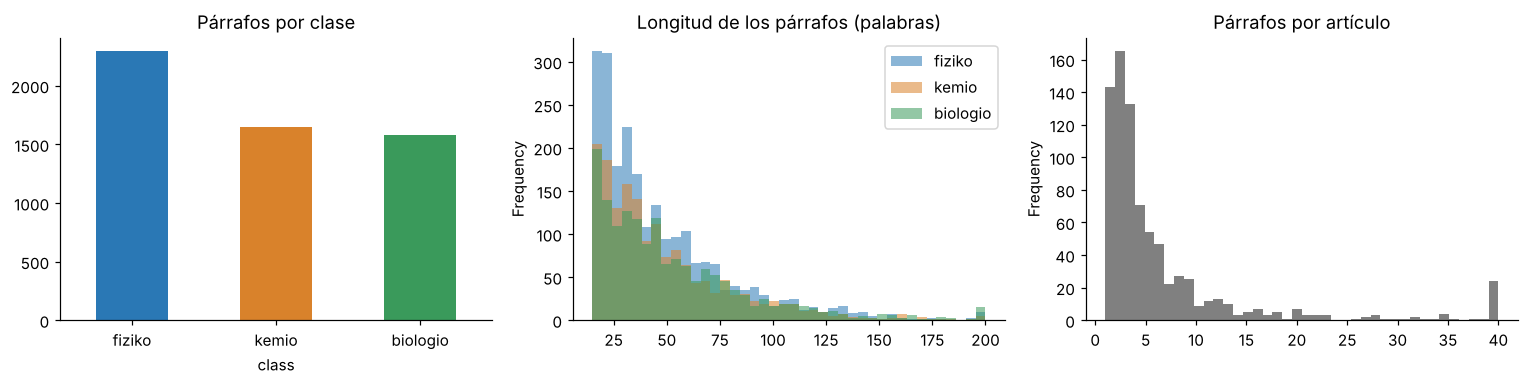

In [6]:
resumen = df.groupby("class").agg(
    parrafos=("text", "size"),
    articulos=("title", "nunique"),
    palabras_media=("text", lambda s: s.str.split().str.len().mean()),
).round(1).loc[list(CATEGORIES)]
display(resumen)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
resumen["parrafos"].plot.bar(ax=axes[0], color=[COLORES[c] for c in resumen.index], rot=0)
axes[0].set_title("Párrafos por clase")
for c in CATEGORIES:
    df.loc[df["class"] == c, "text"].str.split().str.len().clip(upper=200).plot.hist(
        ax=axes[1], bins=40, alpha=0.55, color=COLORES[c], label=c)
axes[1].set_title("Longitud de los párrafos (palabras)"); axes[1].legend()
df.groupby("title").size().clip(upper=40).plot.hist(ax=axes[2], bins=40, color="grey")
axes[2].set_title("Párrafos por artículo")
plt.tight_layout(); plt.show()

El dataset está algo **desbalanceado** (física tiene más párrafos porque sus
artículos son más largos). No se re-muestrea: se usará **F1 macro** como métrica
principal, que pesa igual las tres clases. También hay artículos muy largos
(más de 100 párrafos) que pesan mucho en su clase; por eso la partición
train/test se hace por artículo.

In [7]:
for c in CATEGORIES:
    ejemplo = df[df["class"] == c].sample(1, random_state=SEED).iloc[0]
    print(f"[{c}] ({ejemplo['title']})\n  {ejemplo['text'][:300]}\n")

[fiziko] (Unua leĝo de termodinamiko)
  klare montras, ke la sama volumenpligrandiĝo kaŭzas dum la ekspansio de la adiabata procezo pligrandan malaltigon de la premo ol dum la izoterma ekspansio.

[kemio] (Ĥemia reakcio)
  La difino de Arrhenius: acidoj disociiĝas en akvo delasante H3O+ jonojn, bazoj disociiĝas en akvo delasante OH− jonojn.

[biologio] (Ĝibo)
  Homoj kun ĝibo nomiĝas ĝibuloj. La plej fama - fikcia - ĝibulo estas la romana ludanto de Victor Hugo: Kvazimodo, La sonorilisto de Notre Dame.



### 1.5 Ruido de etiquetado (primera aproximación)

Cada párrafo **hereda la etiqueta de su artículo**, pero muchos párrafos son
genéricos: fechas, historia, biografías... (*"Ĝi estis fondita en 1950"*).
Una medida sencilla del ruido: buscar párrafos que **no contienen ningún término
del dominio**. Se define el vocabulario de dominio con raíces típicas de cada
ciencia (lista propia, sin usar el modelo, para no tener un razonamiento circular).
En la Fase 3 se mide el ruido de una segunda forma, con el propio clasificador.

In [8]:
RAICES_DOMINIO = {
    "fiziko": ["fizik", "energi", "fort", "mas", "rapid", "ond", "lum", "elektr", "magnet",
               "kvantum", "partikl", "gravit", "temperatur", "radiad", "mekanik", "optik",
               "frekvenc", "akcel", "kamp", "relativ"],
    "kemio": ["kemi", "ĥemi", "atom", "molekul", "element", "reakci", "acid", "baz", "jon",
              "metal", "oksid", "kombinaĵ", "solv", "hidrogen", "oksigen", "karbon", "salo",
              "izotop", "kristal", "gas"],
    "biologio": ["biolog", "ĉel", "organism", "speci", "gen", "protein", "plant", "best",
                 "evoluci", "evolu", "histo", "ekolog", "bakteri", "vivaĵ", "hormon",
                 "kromosom", "dna", "sang", "nutr", "reprodukt"],
}
todas = [r for rs in RAICES_DOMINIO.values() for r in rs]
patron = re.compile(r"\b(" + "|".join(todas) + r")", re.IGNORECASE)
df["sin_termino_de_dominio"] = ~df["text"].str.contains(patron)

ruido_heuristico = df.groupby("class")["sin_termino_de_dominio"].mean().mul(100).round(1)
print("% de párrafos sin ningún término científico:")
print(ruido_heuristico.to_string(), f"\nTotal: {df['sin_termino_de_dominio'].mean()*100:.1f} %")
print("\nEjemplos:")
for t in df[df["sin_termino_de_dominio"]].sample(4, random_state=SEED)["text"]:
    print(" ·", t[:160])

% de párrafos sin ningún término científico:
class
biologio    33.6
fiziko      23.3
kemio       12.1 
Total: 22.9 %

Ejemplos:
 · Alia demando pri la temo estas nomita la Fermi Paradokso, nomita laŭ ĝia pensulo Enrico Fermi, kaj ĝi estas 'Se efektive ekzistas inteligenta vivo en la univers
 · Ekzistas pluraj (72, kaj 40 pri morto) proverboj pri vivo en la Proverbaro Esperanta de L. L. Zamenhof, inter ili:
 · En fonologio, tembro estas la distingiga eco de voĉa parolsono, kaŭzata de kombinoj de ĝiaj formantoj.
 · Pli postaj dezajnoj efektivigis vaporliberigan valvon kiu evitis la eksplodon de la maŝino. Rigardante la valvon ritme moviĝi supren kaj malsupren, Papin elpens


## 2. Fase 2 – Modelo de NLP para Esperanto

Se implementa **desde cero** (sin spaCy, NLTK ni Stanza) un modelo basado en
reglas con un API como el de spaCy:

```python
nlp = load()
doc = nlp("La katoj manĝis fiŝon.")
for token in doc:
    token.text, token.lemma_, token.pos_, token.morph, token.is_stop
```

**¿Por qué funcionan las reglas?** El Esperanto marca la categoría gramatical
con la terminación, sin excepciones:

| Terminación | Categoría | Rasgos | Ejemplo → lema |
|---|---|---|---|
| `-o` (`-oj`, `-on`, `-ojn`) | sustantivo `NOUN` | número, caso | *atomojn* → *atomo* |
| `-a` (`-aj`, `-an`, `-ajn`) | adjetivo `ADJ` | número, caso | *kemiajn* → *kemia* |
| `-e` (`-en`) | adverbio `ADV` | dirección | *rapide* → *rapide* |
| `-as` / `-is` / `-os` | verbo `VERB` | presente / pasado / futuro | *trovis* → *trovi* |
| `-us` / `-u` / `-i` | verbo `VERB` | condicional / imperativo / infinitivo | *estu* → *esti* |
| `-ant- -int- -ont- -at- -it- -ot-` | participio | aspecto, voz | *skribita* → *skribi* |

Las palabras que no siguen estas reglas son de **clase cerrada** (artículo,
pronombres, la tabla de 45 correlativos, preposiciones, conjunciones,
numerales...) y se buscan en un **léxico** antes de aplicar las reglas.

**Pipeline** (`nlp.pipe_names`):

1. `normalizer`: Unicode NFC, apóstrofos y **sistema‑x** (`cx` → `ĉ`, `sx` → `ŝ`).
2. `tokenizer`: expresión regular (palabras con guion y elisión `l'`, números, URLs, signos).
3. `tagger`: UPOS + rasgos morfológicos (Universal Dependencies) por léxico y terminaciones.
   Mayúscula en mitad de oración → `PROPN`; letras `q w x y` → palabra extranjera.
4. `lemmatizer`: forma de diccionario y **descomposición en morfemas**
   (`malsanulejo` → `mal + san + ul + ej + o`) con prefijos/sufijos oficiales.
5. `stopwords`: `token.is_stop` a partir de una lista de **lemas** (así *estas,
   estis, estos* son todas stop-word por el lema *esti*).

También unifica variantes ortográficas con *ĥ* (*ĥemio* → *kemio*), muy
frecuentes en Vikipedio.

In [9]:
# ===== Código de eonlp/lexicon.py =====
"""Léxico cerrado del Esperanto.

El Esperanto tiene una gramática regular: casi todas las palabras "abiertas"
(sustantivos, adjetivos, verbos y adverbios derivados) se reconocen por su
terminación. Las excepciones son las palabras de clase cerrada (artículo,
pronombres, correlativos, preposiciones, conjunciones, numerales, adverbios
primarios...). Este módulo las enumera para que el etiquetador las reconozca
antes de aplicar las reglas de terminaciones.

Fuente: gramática básica del Esperanto (Fundamento de Esperanto, 16 reglas)
y la guía de la asignatura (nlp-esperantilo).
"""

# --------------------------------------------------------------------------
# Artículo
# --------------------------------------------------------------------------
ARTICLES = {"la", "l'"}

# --------------------------------------------------------------------------
# Pronombres personales (y sus formas en acusativo) y posesivos
# --------------------------------------------------------------------------
PERSONAL_PRONOUNS = ["mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si", "ci"]

# --------------------------------------------------------------------------
# Correlativos: tabla de 5 prefijos x 9 sufijos
#   ki- (interrogativo), ti- (demostrativo), i- (indefinido),
#   ĉi- (universal), neni- (negativo)
# --------------------------------------------------------------------------
CORRELATIVE_PREFIXES = ["ki", "ti", "i", "ĉi", "neni"]
# sufijo -> (categoría UPOS, significado)
CORRELATIVE_SUFFIXES = {
    "u": ("DET", "individuo"),     # kiu, tiu, iu, ĉiu, neniu  (declinable: -j, -n)
    "o": ("PRON", "cosa"),         # kio, tio, io, ĉio, nenio   (declinable: -n)
    "a": ("DET", "cualidad"),      # kia, tia, ...              (declinable: -j, -n)
    "e": ("ADV", "lugar"),         # kie, tie, ...              (-n = dirección)
    "am": ("ADV", "tiempo"),       # kiam, tiam, ...
    "el": ("ADV", "modo"),         # kiel, tiel, ...
    "om": ("ADV", "cantidad"),     # kiom, tiom, ...
    "al": ("ADV", "causa"),        # kial, tial, ...
    "es": ("DET", "posesión"),     # kies, ties, ...
}

PREPOSITIONS = {
    "al", "anstataŭ", "antaŭ", "apud", "da", "de", "dum", "ekster", "el", "en",
    "ĝis", "inter", "je", "kontraŭ", "krom", "kun", "laŭ", "malgraŭ", "per",
    "po", "por", "post", "preter", "pri", "pro", "sen", "sub", "super", "sur",
    "tra", "trans", "ĉe", "ĉirkaŭ", "cis", "kontraŭe", "fare",
}

CONJUNCTIONS = {
    "kaj", "aŭ", "sed", "nek", "do", "ĉar", "ke", "se", "kvankam", "ĉu",
    "kvazaŭ", "dum", "ol", "tamen", "ju", "des", "nome", "plus", "minus",
}

# Adverbios primarios (no terminan en -e de forma regular)
PRIMARY_ADVERBS = {
    "ankaŭ", "ankoraŭ", "apenaŭ", "baldaŭ", "eĉ", "for", "hieraŭ", "hodiaŭ",
    "jam", "ja", "jen", "morgaŭ", "ne", "jes", "nun", "nur", "plu", "pli",
    "plej", "preskaŭ", "tre", "tro", "tuj", "ĉi", "almenaŭ", "adiaŭ", "mem",
    "ajn", "ambaŭ", "kvazaŭ", "malpli", "malplej", "ĉiam", "neniam", "iom",
    "tiel", "kiel", "ankoraŭfoje",
}

PARTICLES = {"ajn", "ĉi", "ja", "jen", "mem", "nur", "eĉ"}

INTERJECTIONS = {"ho", "ha", "ve", "nu", "fi", "hura", "aĥ", "ehe", "hej", "bis", "saluton", "dankon"}

# Abreviaturas frecuentes: ktp (kaj tiel plu = etc.), ekz (ekzemple), ks (kaj simile)...
ABBREVIATIONS = {"ktp", "ekz", "ks", "kp", "vd", "ĉ", "pp", "ktr", "resp", "bv", "sk"}

# Numerales cardinales básicos
NUMERAL_UNITS = ["unu", "du", "tri", "kvar", "kvin", "ses", "sep", "ok", "naŭ"]
NUMERAL_WORDS = set(NUMERAL_UNITS) | {"nul", "dek", "cent", "mil"}

# Verbos auxiliares / muy frecuentes que se tratan como stop-words por lema
AUXILIARY_VERBS = {"esti", "havi", "povi", "devi", "voli", "fari", "iĝi", "igi", "ŝajni"}


def correlatives():
    """Genera la tabla completa de correlativos con sus formas declinadas.

    Devuelve un diccionario ``forma -> (upos, lema, rasgos)``.
    """
    table = {}
    for pre in CORRELATIVE_PREFIXES:
        for suf, (upos, _meaning) in CORRELATIVE_SUFFIXES.items():
            base = pre + suf
            table[base] = (upos, base, {"PronType": _pron_type(pre)})
            if suf in ("u", "a"):
                table[base + "j"] = (upos, base, {"PronType": _pron_type(pre), "Number": "Plur"})
                table[base + "n"] = (upos, base, {"PronType": _pron_type(pre), "Case": "Acc"})
                table[base + "jn"] = (upos, base, {"PronType": _pron_type(pre), "Number": "Plur", "Case": "Acc"})
            elif suf == "o":
                table[base + "n"] = (upos, base, {"PronType": _pron_type(pre), "Case": "Acc"})
            elif suf == "e":
                table[base + "n"] = (upos, base, {"PronType": _pron_type(pre), "Case": "Acc"})
    return table


def _pron_type(prefix):
    return {"ki": "Int", "ti": "Dem", "i": "Ind", "ĉi": "Tot", "neni": "Neg"}[prefix]


def pronouns():
    """Pronombres personales, posesivos y sus formas declinadas.

    Devuelve un diccionario ``forma -> (upos, lema, rasgos)``.
    """
    table = {}
    for p in PERSONAL_PRONOUNS:
        table[p] = ("PRON", p, {"PronType": "Prs"})
        table[p + "n"] = ("PRON", p, {"PronType": "Prs", "Case": "Acc"})
        poss = p + "a"  # mia, via, lia, ŝia, ĝia, nia, ilia, onia, sia
        table[poss] = ("DET", poss, {"Poss": "Yes"})
        table[poss + "j"] = ("DET", poss, {"Poss": "Yes", "Number": "Plur"})
        table[poss + "n"] = ("DET", poss, {"Poss": "Yes", "Case": "Acc"})
        table[poss + "jn"] = ("DET", poss, {"Poss": "Yes", "Number": "Plur", "Case": "Acc"})
    return table


def closed_class_lexicon():
    """Construye el léxico completo de palabras de clase cerrada.

    El orden importa: las entradas posteriores sobrescriben a las anteriores
    (p. ej. ``ĉi`` es a la vez prefijo correlativo y partícula).
    Devuelve ``forma -> (upos, lema, rasgos)``.
    """
    lex = {}
    for w in NUMERAL_WORDS:
        lex[w] = ("NUM", w, {"NumType": "Card"})
    for w in INTERJECTIONS:
        lex[w] = ("INTJ", w, {})
    for w in PRIMARY_ADVERBS:
        lex[w] = ("ADV", w, {})
    for w in ABBREVIATIONS:
        lex[w] = ("X", w, {"Abbr": "Yes"})
    for w in CONJUNCTIONS:
        upos = "SCONJ" if w in {"ke", "se", "ĉar", "kvankam", "ĉu", "kvazaŭ", "dum", "ol"} else "CCONJ"
        lex[w] = (upos, w, {})
    for w in PREPOSITIONS:
        lex[w] = ("ADP", w, {})
    lex.update(correlatives())
    lex.update(pronouns())
    for w in PARTICLES:
        lex[w] = ("PART", w, {})
    for w in ARTICLES:
        lex[w] = ("DET", "la", {"Definite": "Def", "PronType": "Art"})
    # "dum" es preposición y conjunción; dejamos ADP como más frecuente.
    lex["dum"] = ("ADP", "dum", {})
    return lex


# --------------------------------------------------------------------------
# Stop-words
# --------------------------------------------------------------------------
def default_stop_words():
    """Lista de stop-words: todas las palabras de clase cerrada + verbos auxiliares.

    Se guarda como conjunto de **lemas**, de forma que cualquier forma
    flexionada (``estas``, ``estis``, ``tiujn``...) se considera stop-word.
    """
    stops = {lemma for (_upos, lemma, _f) in closed_class_lexicon().values()}
    stops |= set(closed_class_lexicon())
    stops |= AUXILIARY_VERBS
    # palabras muy frecuentes sin carga temática en textos enciclopédicos
    stops |= {
        "multa", "multe", "pli", "alia", "sama", "nova", "unua", "dua", "tria",
        "granda", "malgranda", "bona", "nomi", "uzi", "ekzisti", "trovi",
        "jaro", "parto", "ekzemplo", "ekzemple", "speco", "tipo", "kelka",
        "diversa", "simila", "grava", "ofte", "kutime", "ĝenerale", "nomo",
    }
    return stops

In [10]:
# ===== Código de eonlp/nlp.py =====
"""Modelo de NLP para Esperanto basado en reglas, con un API similar a spaCy.

Uso::

    nlp = load()
    doc = nlp("La katoj manĝis fiŝon.")
    for token in doc:
        print(token.text, token.lemma_, token.pos_, token.morph, token.is_stop)

Componentes del pipeline (``nlp.pipe_names``):

1. ``normalizer``  - normaliza Unicode y el sistema-x (``cx`` -> ``ĉ``).
2. ``tokenizer``   - divide el texto en tokens con expresiones regulares.
3. ``tagger``      - etiquetado gramatical (UPOS) y morfológico por terminaciones.
4. ``lemmatizer``  - forma de diccionario (``-o``, ``-a``, ``-i``, ``-e``).
5. ``stopwords``   - marca ``token.is_stop`` a partir de una lista de lemas.

Todo está implementado desde cero, sin librerías de NLP: el Esperanto es
regular y sin excepciones, así que unas pocas reglas cubren la mayoría de casos.
"""

import re
import unicodedata


# --------------------------------------------------------------------------
# Normalización
# --------------------------------------------------------------------------
# Sistema-x: forma habitual de escribir Esperanto sin teclado especial.
X_SYSTEM = {
    "cx": "ĉ", "gx": "ĝ", "hx": "ĥ", "jx": "ĵ", "sx": "ŝ", "ux": "ŭ",
    "Cx": "Ĉ", "Gx": "Ĝ", "Hx": "Ĥ", "Jx": "Ĵ", "Sx": "Ŝ", "Ux": "Ŭ",
    "CX": "Ĉ", "GX": "Ĝ", "HX": "Ĥ", "JX": "Ĵ", "SX": "Ŝ", "UX": "Ŭ",
}
_X_RE = re.compile("|".join(X_SYSTEM))


# Variantes ortográficas con "ĥ" que hoy se escriben con "k"
# (ĥemio -> kemio, teĥniko -> tekniko...). Se unifican para que el modelo
# vea una sola forma de cada raíz.
H_VARIANTS = {"ĥem": "kem", "ĥlor": "klor", "ĥrom": "krom", "ĥaos": "kaos",
              "teĥn": "tekn", "meĥan": "mekan", "arĥe": "arke", "ĥiral": "kiral",
              "ĥoler": "koler", "ĥirurg": "kirurg"}
_H_RE = re.compile("|".join(H_VARIANTS), re.IGNORECASE)


def unify_spelling(word):
    """Unifica variantes ortográficas: ``bioĥemia`` -> ``biokemia``."""
    if "ĥ" not in word.lower():
        return word
    return _H_RE.sub(lambda m: H_VARIANTS[m.group(0).lower()], word)


def normalize_text(text, x_system=True):
    """Normaliza a NFC (letras con diacrítico en un solo carácter) y,
    opcionalmente, convierte el sistema-x a letras con diacrítico."""
    text = unicodedata.normalize("NFC", text)
    # comillas y apóstrofos tipográficos -> ASCII
    text = text.replace("’", "'").replace("‘", "'").replace("´", "'")
    if x_system:
        text = _X_RE.sub(lambda m: X_SYSTEM[m.group(0)], text)
    return text


# --------------------------------------------------------------------------
# Tokenizador
# --------------------------------------------------------------------------
ESPERANTO_LETTERS = "a-zA-ZĉĝĥĵŝŭĈĜĤĴŜŬ"
_TOKEN_RE = re.compile(
    rf"""
    (?P<url>https?://\S+)                                   # URLs
  | (?P<num>\d+(?:[.,]\d+)*)                                # números: 1 000, 3,14
  | (?P<word>[\w]+(?:[-'][\w]+)*'?)                         # palabras (incl. guion y elisión l')
  | (?P<punct>[^\w\s])                                      # signos de puntuación
    """,
    re.VERBOSE | re.UNICODE,
)


def tokenize(text):
    """Devuelve una lista de tuplas ``(texto, posición, espacio_posterior)``."""
    out = []
    for m in _TOKEN_RE.finditer(text):
        start, end = m.span()
        ws = text[end:end + 1] if end < len(text) and text[end].isspace() else ""
        out.append((m.group(0), start, ws))
    return out


# --------------------------------------------------------------------------
# Objetos Token y Doc (API tipo spaCy)
# --------------------------------------------------------------------------
class MorphAnalysis(dict):
    """Rasgos morfológicos (``Number=Plur|Case=Acc``) al estilo Universal Dependencies."""

    def __str__(self):
        return "|".join(f"{k}={v}" for k, v in sorted(self.items()))

    def get(self, key, default=None):  # noqa: D401 - igual que dict.get
        return super().get(key, default)


class Token:
    """Un token del documento.

    Atributos principales (mismos nombres que spaCy):
    ``text``, ``i``, ``idx``, ``whitespace_``, ``lemma_``, ``pos_``, ``tag_``,
    ``morph``, ``is_stop``, ``is_punct``, ``is_alpha``, ``like_num``, ``like_url``.
    Extra propio: ``root_`` (raíz sin terminación gramatical) y ``morphemes``.
    """

    __slots__ = ("doc", "text", "i", "idx", "whitespace_", "lemma_", "pos_",
                 "tag_", "morph", "is_stop", "root_", "morphemes")

    def __init__(self, doc, text, i, idx, whitespace=""):
        self.doc = doc
        self.text = text
        self.i = i
        self.idx = idx
        self.whitespace_ = whitespace
        self.lemma_ = text.lower()
        self.pos_ = "X"
        self.tag_ = ""
        self.morph = MorphAnalysis()
        self.is_stop = False
        self.root_ = text.lower()
        self.morphemes = [text.lower()]

    # propiedades derivadas -------------------------------------------------
    @property
    def lower_(self):
        return self.text.lower()

    @property
    def text_with_ws(self):
        return self.text + self.whitespace_

    @property
    def is_punct(self):
        return self.pos_ == "PUNCT"

    @property
    def is_alpha(self):
        return self.text.replace("'", "").isalpha()

    @property
    def is_digit(self):
        return self.text.isdigit()

    @property
    def like_num(self):
        return self.pos_ == "NUM"

    @property
    def like_url(self):
        return self.text.startswith(("http://", "https://"))

    @property
    def is_sent_start(self):
        return self.i == 0 or self.doc[self.i - 1].text in {".", "!", "?"}

    def __len__(self):
        return len(self.text)

    def __str__(self):
        return self.text

    def __repr__(self):
        return self.text


class Span:
    """Secuencia contigua de tokens (se usa para las oraciones)."""

    def __init__(self, doc, start, end):
        self.doc, self.start, self.end = doc, start, end

    def __iter__(self):
        return iter(self.doc.tokens[self.start:self.end])

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, i):
        return self.doc.tokens[self.start:self.end][i]

    @property
    def text(self):
        return "".join(t.text_with_ws for t in self).strip()

    def __repr__(self):
        return self.text


class Doc:
    """Documento procesado: contenedor de ``Token`` en orden."""

    def __init__(self, text, words=None):
        self.text = text
        self.tokens = []
        for i, (w, idx, ws) in enumerate(words or []):
            self.tokens.append(Token(self, w, i, idx, ws))

    def __iter__(self):
        return iter(self.tokens)

    def __len__(self):
        return len(self.tokens)

    def __getitem__(self, i):
        if isinstance(i, slice):
            start, stop, _ = i.indices(len(self))
            return Span(self, start, stop)
        return self.tokens[i]

    @property
    def sents(self):
        """Segmentación en oraciones por signos de puntuación final."""
        start = 0
        for t in self.tokens:
            if t.text in {".", "!", "?"}:
                yield Span(self, start, t.i + 1)
                start = t.i + 1
        if start < len(self.tokens):
            yield Span(self, start, len(self.tokens))

    def to_table(self):
        """Lista de diccionarios (cómodo para crear un ``pandas.DataFrame``)."""
        return [
            {"text": t.text, "lemma": t.lemma_, "pos": t.pos_, "tag": t.tag_,
             "morph": str(t.morph), "root": t.root_, "is_stop": t.is_stop}
            for t in self.tokens
        ]

    def __repr__(self):
        return self.text


# --------------------------------------------------------------------------
# Análisis morfológico por terminaciones
# --------------------------------------------------------------------------
# Terminaciones verbales: tiempo/modo
VERB_ENDINGS = {
    "as": {"Tense": "Pres", "Mood": "Ind", "VerbForm": "Fin"},
    "is": {"Tense": "Past", "Mood": "Ind", "VerbForm": "Fin"},
    "os": {"Tense": "Fut", "Mood": "Ind", "VerbForm": "Fin"},
    "us": {"Mood": "Cnd", "VerbForm": "Fin"},
    "u": {"Mood": "Imp", "VerbForm": "Fin"},
    "i": {"VerbForm": "Inf"},
}

# Sufijos de participio: (aspecto, tiempo, voz)
PARTICIPLES = {
    "ant": ("Imp", "Pres", "Act"), "int": ("Perf", "Past", "Act"), "ont": ("Prosp", "Fut", "Act"),
    "at": ("Imp", "Pres", "Pass"), "it": ("Perf", "Past", "Pass"), "ot": ("Prosp", "Fut", "Pass"),
}
# Palabras que parecen participios pero no lo son (raíz lexicalizada)
PARTICIPLE_EXCEPTIONS = {
    "konstanta", "konstante", "elefanta", "kvanta", "privata", "delikata", "akurata",
    "adekvata", "infinita", "eksplicita", "implicita", "favorita", "granda",
    "kandidata", "senata", "pirata", "kvalita", "klimata", "simpatia", "planta",
    "giganta", "elegante", "eleganta", "brilanta", "variante", "konsonanta",
    "elita", "spirita", "merita", "subita", "subite", "limita", "unuopa", "dekstra",
    "kalkulita", "sankta", "akcidenta", "frekventa", "inteligenta", "potenca",
    "kompetenta", "evidenta", "evidente", "permanenta", "permanente", "absoluta",
    "absolute", "pacienta", "studenta", "doktoranta", "abunda",
}
MIN_STEM = 2  # longitud mínima de raíz para aceptar una terminación

# Afijos (para descomponer en morfemas: mal-san-ul-ej-o)
PREFIXES = ["mal", "re", "ek", "dis", "ge", "eks", "bo", "fi", "mis", "pra", "for", "ne"]
SUFFIXES = ["ad", "aĉ", "aĵ", "an", "ar", "ec", "eg", "ej", "em", "end", "er", "estr",
            "et", "id", "ig", "iĝ", "il", "in", "ind", "ing", "ism", "ist", "obl", "on",
            "op", "uj", "ul", "um"]

_NUM_RE = re.compile(
    r"^(?:(?:" + "|".join(NUMERAL_UNITS) + r")?(?:dek|cent|mil))+(?:" + "|".join(NUMERAL_UNITS) + r")?$"
)
_FOREIGN_RE = re.compile(r"[qwxyQWXY]")


def split_morphemes(stem, min_root=3):
    """Descompone (de forma voraz) una raíz en prefijos + raíz + sufijos.

    ``malsanulejo`` -> raíz ``malsanulej`` -> ``['mal', 'san', 'ul', 'ej']``.
    Solo se separa un afijo si la raíz restante conserva ``min_root`` letras,
    para no destrozar raíces cortas (``ideo`` no es ``id-eo``).
    """
    prefixes, suffixes = [], []
    changed = True
    while changed:
        changed = False
        for p in PREFIXES:
            if stem.startswith(p) and len(stem) - len(p) >= min_root + 1:
                prefixes.append(p)
                stem = stem[len(p):]
                changed = True
                break
    changed = True
    while changed:
        changed = False
        for s in sorted(SUFFIXES, key=len, reverse=True):
            if stem.endswith(s) and len(stem) - len(s) >= min_root:
                suffixes.insert(0, s)
                stem = stem[: -len(s)]
                changed = True
                break
    return prefixes + [stem] + suffixes


class EsperantoAnalyzer:
    """Etiquetador + lematizador basado en reglas.

    Devuelve, para una palabra, ``(upos, lemma, rasgos, raíz)``.
    """

    def __init__(self):
        self.lexicon = closed_class_lexicon()

    def analyze(self, word, sent_start=False):
        low = unify_spelling(word.lower())

        # 1. Puntuación y números ------------------------------------------
        if not any(ch.isalnum() for ch in word):
            return "PUNCT", word, {}, word
        if word.replace(".", "").replace(",", "").isdigit():
            return "NUM", word, {"NumType": "Card"}, word
        if word.startswith(("http://", "https://")):
            return "X", word, {}, word

        # 2. Léxico cerrado -------------------------------------------------
        if low in self.lexicon:
            upos, lemma, feats = self.lexicon[low]
            return upos, lemma, dict(feats), lemma
        if _NUM_RE.match(low):
            return "NUM", low, {"NumType": "Card"}, low

        # 3. Elisión poética: "kor'" = "koro"
        if low.endswith("'") and len(low) > 2:
            return "NOUN", low[:-1] + "o", {"Number": "Sing", "Case": "Nom"}, low[:-1]

        # 4. Nombres propios y palabras extranjeras ------------------------
        is_capital = word[:1].isupper()
        if _FOREIGN_RE.search(low) or any(ch.isdigit() for ch in low):
            return ("PROPN" if is_capital else "X"), word, {"Foreign": "Yes"}, low
        if is_capital and not sent_start and not self._has_eo_ending(low):
            return "PROPN", word, {}, low

        # 5. Reglas de terminación (núcleo del modelo) ---------------------
        res = self._by_ending(low)
        if res is not None:
            upos, lemma, feats, root = res
            if is_capital and not sent_start:
                # En mitad de la oración, la mayúscula indica nombre propio
                # ("Eŭropo", "Parizo", "Marie Curie"). Los adjetivos de
                # nacionalidad se escriben en minúscula en Esperanto.
                upos = "PROPN"
                lemma = word[:1] + lemma[1:] if res[0] == "NOUN" else word
            return upos, lemma, feats, root

        return ("PROPN" if is_capital else "X"), word if is_capital else low, {}, low

    # ------------------------------------------------------------------
    @staticmethod
    def _has_eo_ending(low):
        return bool(re.search(r"(o|oj|on|ojn|a|aj|an|ajn|e|en|as|is|os|us|u|i)$", low))

    def _by_ending(self, low):
        # Sustantivos: -o(j)(n)
        m = re.match(r"^(.+?)o(j?)(n?)$", low)
        if m and len(m.group(1)) >= MIN_STEM:
            stem = m.group(1)
            feats = {"Number": "Plur" if m.group(2) else "Sing", "Case": "Acc" if m.group(3) else "Nom"}
            return "NOUN", stem + "o", feats, stem

        # Adjetivos: -a(j)(n)  (pueden ser participios: -ant-a, -it-a...)
        m = re.match(r"^(.+?)a(j?)(n?)$", low)
        if m and len(m.group(1)) >= MIN_STEM:
            stem = m.group(1)
            feats = {"Number": "Plur" if m.group(2) else "Sing", "Case": "Acc" if m.group(3) else "Nom"}
            part = self._participle(stem, low)
            if part:
                verb_stem, pfeats = part
                feats.update(pfeats)
                return "ADJ", verb_stem + "i", feats, verb_stem
            if stem in NUMERAL_UNITS or stem in {"dek", "cent", "mil"} or _NUM_RE.match(stem):
                feats["NumType"] = "Ord"     # dua, tria, dudeka...
            return "ADJ", stem + "a", feats, stem

        # Adverbios derivados: -e(n)
        m = re.match(r"^(.+?)e(n?)$", low)
        if m and len(m.group(1)) >= MIN_STEM:
            stem = m.group(1)
            feats = {"Case": "Acc"} if m.group(2) else {}   # -en = dirección (hejmen)
            part = self._participle(stem, low)
            if part:
                verb_stem, pfeats = part
                feats.update(pfeats)
                return "ADV", verb_stem + "i", feats, verb_stem
            return "ADV", stem + "e", feats, stem

        # Verbos: -as, -is, -os, -us, -u, -i
        for ending in ("as", "is", "os", "us", "u", "i"):
            if low.endswith(ending) and len(low) - len(ending) >= MIN_STEM:
                stem = low[: -len(ending)]
                return "VERB", stem + "i", dict(VERB_ENDINGS[ending]), stem
        return None

    @staticmethod
    def _participle(stem, word):
        """Si ``stem`` termina en un sufijo de participio, devuelve la raíz verbal."""
        if word in PARTICIPLE_EXCEPTIONS:
            return None
        for suf, (aspect, tense, voice) in PARTICIPLES.items():
            if stem.endswith(suf) and len(stem) - len(suf) >= 3:
                return stem[: -len(suf)], {"VerbForm": "Part", "Aspect": aspect,
                                            "Tense": tense, "Voice": voice}
        return None


# --------------------------------------------------------------------------
# Pipeline estilo spaCy
# --------------------------------------------------------------------------
class Esperanto:
    """Objeto ``nlp``: aplica el pipeline completo a un texto y devuelve un ``Doc``."""

    lang = "eo"

    def __init__(self, stop_words=None, x_system=True):
        self.x_system = x_system
        self.analyzer = EsperantoAnalyzer()
        self.stop_words = set(stop_words) if stop_words is not None else default_stop_words()
        self.pipeline = [
            ("tagger", self._tagger),
            ("lemmatizer", self._lemmatizer),
            ("stopwords", self._stopwords),
        ]

    @property
    def pipe_names(self):
        return ["normalizer", "tokenizer"] + [name for name, _ in self.pipeline]

    # API pública ---------------------------------------------------------
    def make_doc(self, text):
        """Normaliza y tokeniza (sin el resto del pipeline)."""
        text = normalize_text(text, self.x_system)
        return Doc(text, tokenize(text))

    def __call__(self, text):
        doc = self.make_doc(text)
        for _name, component in self.pipeline:
            doc = component(doc)
        return doc

    def pipe(self, texts):
        """Procesa un iterable de textos (generador, como ``spacy.Language.pipe``)."""
        for text in texts:
            yield self(text)

    def add_stop_words(self, words):
        self.stop_words |= {w.lower() for w in words}

    # Componentes ---------------------------------------------------------
    def _tagger(self, doc):
        for tok in doc:
            upos, lemma, feats, root = self.analyzer.analyze(tok.text, tok.is_sent_start)
            tok.pos_ = upos
            tok.morph = MorphAnalysis(feats)
            tok.tag_ = upos + ("__" + str(tok.morph) if feats else "")
            tok.lemma_ = lemma   # se guarda aquí y lo confirma el lematizador
            tok.root_ = root
        return doc

    def _lemmatizer(self, doc):
        for tok in doc:
            if tok.pos_ in {"NOUN", "ADJ", "VERB", "ADV"}:
                tok.lemma_ = tok.lemma_.lower()
                tok.morphemes = split_morphemes(tok.root_)
            elif tok.pos_ == "PROPN":
                tok.morphemes = [tok.root_]
            else:
                tok.morphemes = [tok.lemma_.lower()]
        return doc

    def _stopwords(self, doc):
        for tok in doc:
            tok.is_stop = tok.lower_ in self.stop_words or tok.lemma_.lower() in self.stop_words
        return doc

    def __repr__(self):
        return f"<Esperanto nlp pipeline={self.pipe_names}>"


def load(**kwargs):
    """Equivalente a ``spacy.load(...)``: devuelve el pipeline listo para usar."""
    return Esperanto(**kwargs)

### 2.1 Demostración del API

In [11]:
nlp = load()
print(nlp)
doc = nlp("La junaj sciencistoj malkovris novajn elementojn en la laboratorio de Marie Curie, "
          "kaj ili skribos artikolon pri la radioaktiveco.")
pd.DataFrame(doc.to_table())

<Esperanto nlp pipeline=['normalizer', 'tokenizer', 'tagger', 'lemmatizer', 'stopwords']>


,text,lemma,pos,tag,morph,root,is_stop
0,La,la,DET,DET__Definite=Def|PronType=Art,Definite=Def|PronType=Art,la,True
1,junaj,juna,ADJ,ADJ__Case=Nom|Number=Plur,Case=Nom|Number=Plur,jun,False
2,sciencistoj,sciencisto,NOUN,NOUN__Case=Nom|Number=Plur,Case=Nom|Number=Plur,sciencist,False
3,malkovris,malkovri,VERB,VERB__Mood=Ind|Tense=Past|VerbForm=Fin,Mood=Ind|Tense=Past|VerbForm=Fin,malkovr,False
4,novajn,nova,ADJ,ADJ__Case=Acc|Number=Plur,Case=Acc|Number=Plur,nov,True
5,elementojn,elemento,NOUN,NOUN__Case=Acc|Number=Plur,Case=Acc|Number=Plur,element,False
6,en,en,ADP,ADP,,en,True
7,la,la,DET,DET__Definite=Def|PronType=Art,Definite=Def|PronType=Art,la,True
8,laboratorio,laboratorio,NOUN,NOUN__Case=Nom|Number=Sing,Case=Nom|Number=Sing,laboratori,False
9,de,de,ADP,ADP,,de,True


In [12]:
# Oraciones, morfemas, sistema-x y stop-words
doc = nlp("Mi sxatas la malsanulejon. Cxu vi vidis la ĉielarkon hieraŭ?")
print("Oraciones:", [s.text for s in doc.sents])
print("Normalizado (sistema-x):", doc.text)
for palabra in ["malsanulejo", "ĉielarko", "lernejestro", "maljuneco", "fotosintezo"]:
    print(f"  {palabra:<12} → morfemas {nlp(palabra)[0].morphemes}")
print("Stop-words en el texto:", [t.text for t in doc if t.is_stop])
print("Tamaño de la lista de stop-words:", len(nlp.stop_words))

Oraciones: ['Mi ŝatas la malsanulejon.', 'Ĉu vi vidis la ĉielarkon hieraŭ?']
Normalizado (sistema-x): Mi ŝatas la malsanulejon. Ĉu vi vidis la ĉielarkon hieraŭ?
  malsanulejo  → morfemas ['mal', 'san', 'ul', 'ej']
  ĉielarko     → morfemas ['ĉielark']
  lernejestro  → morfemas ['lern', 'ej', 'estr']
  maljuneco    → morfemas ['mal', 'jun', 'ec']
  fotosintezo  → morfemas ['fotosintez']
Stop-words en el texto: ['Mi', 'la', 'Ĉu', 'vi', 'la', 'hieraŭ']
Tamaño de la lista de stop-words: 307


### 2.2 Evaluación del modelo sobre un pequeño *gold standard*

Para comprobar que el etiquetador funciona se anotan a mano unas frases
(etiqueta UPOS y lema esperados) y se mide la exactitud.

In [13]:
GOLD = [
    ("La katoj manĝis fiŝon .", "DET NOUN VERB NOUN PUNCT", "la kato manĝi fiŝo ."),
    ("Mi ŝatas legi interesajn librojn .", "PRON VERB VERB ADJ NOUN PUNCT", "mi ŝati legi interesa libro ."),
    ("Kiuj sciencistoj malkovris la elektronon ?", "DET NOUN VERB DET NOUN PUNCT", "kiu sciencisto malkovri la elektrono ?"),
    ("La akvo bolas je cent gradoj .", "DET NOUN VERB ADP NUM NOUN PUNCT", "la akvo boli je cent grado ."),
    ("Ŝi iras hejmen rapide ĉar pluvas .", "PRON VERB ADV ADV SCONJ VERB PUNCT", "ŝi iri hejme rapide ĉar pluvi ."),
    ("Ĉiuj vivaj ĉeloj enhavas DNA kaj proteinojn .", "DET ADJ NOUN VERB PROPN CCONJ NOUN PUNCT", "ĉiu viva ĉelo enhavi DNA kaj proteino ."),
    ("La skribita letero estis sendita al Parizo .", "DET ADJ NOUN VERB ADJ ADP PROPN PUNCT", "la skribi letero esti sendi al Parizo ."),
    ("Se vi volus , ni povus helpi vin .", "SCONJ PRON VERB PUNCT PRON VERB VERB PRON PUNCT", "se vi voli , ni povi helpi vi ."),
    ("Tiu ĉi reakcio produktas varmon kaj lumon .", "DET PART NOUN VERB NOUN CCONJ NOUN PUNCT", "tiu ĉi reakcio produkti varmo kaj lumo ."),
    ("La dua leĝo de Newton priskribas la forton .", "DET ADJ NOUN ADP PROPN VERB DET NOUN PUNCT", "la dua leĝo de Newton priskribi la forto ."),
]
aciertos_pos = aciertos_lema = total = 0
errores = []
for frase, pos, lemas in GOLD:
    doc = nlp(frase)
    for tok, p, l in zip(doc, pos.split(), lemas.split()):
        total += 1
        aciertos_pos += tok.pos_ == p
        aciertos_lema += tok.lemma_ == l
        if tok.pos_ != p or tok.lemma_ != l:
            errores.append((tok.text, tok.pos_, p, tok.lemma_, l))
print(f"Exactitud POS:   {aciertos_pos/total:.1%}  ({total} tokens)")
print(f"Exactitud lemas: {aciertos_lema/total:.1%}")
if errores:
    display(pd.DataFrame(errores, columns=["token", "pos_pred", "pos_gold", "lema_pred", "lema_gold"]))

Exactitud POS:   100.0%  (73 tokens)
Exactitud lemas: 100.0%


### 2.3 El modelo sobre el corpus

Distribución de categorías gramaticales en el dataset y palabras que el modelo
no sabe clasificar (`X`). Esto sirve para detectar casos que las reglas no
cubren (palabras extranjeras, fórmulas químicas, abreviaturas).

5518 párrafos procesados en 2.6 s (317,592 tokens)


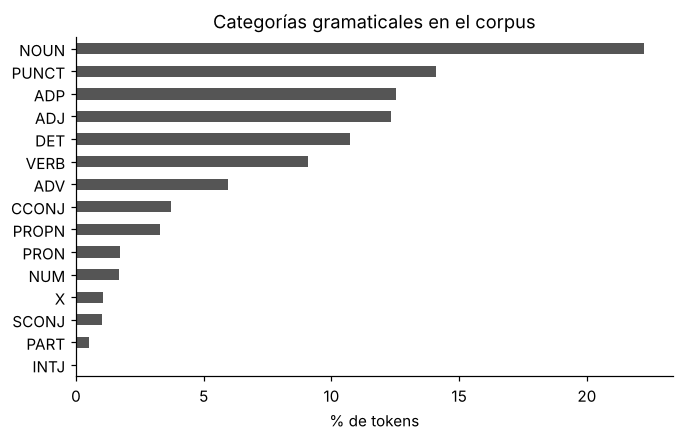

Palabras más frecuentes etiquetadas como X: ['a', 't', 'ktp', 'ekz', 'e', 'n', 'm', 's', 'k', 'dB', 'aj', 'v', 'p', 'of', 'pH']


In [14]:
t0 = time.time()
docs = list(nlp.pipe(df["text"]))
print(f"{len(docs)} párrafos procesados en {time.time() - t0:.1f} s "
      f"({sum(len(d) for d in docs):,} tokens)")

conteo_pos = pd.Series([t.pos_ for d in docs for t in d]).value_counts()
ax = (conteo_pos / conteo_pos.sum() * 100).plot.barh(figsize=(7, 4), color="#555")
ax.invert_yaxis(); ax.set_xlabel("% de tokens"); ax.set_title("Categorías gramaticales en el corpus")
plt.show()
desconocidas = pd.Series([t.text for d in docs for t in d if t.pos_ == "X"]).value_counts()
print("Palabras más frecuentes etiquetadas como X:", list(desconocidas.head(15).index))

## 3. Fase 3 – Clasificación

### 3.1 Representación tabular (vectorización)

Cada párrafo se convierte, con el modelo de la Fase 2, en la lista de
**lemas de las palabras con contenido** (sustantivos, nombres propios,
adjetivos, verbos y adverbios), sin stop-words, números ni signos. Después se
aplica **TF-IDF** (`sublinear_tf`, `min_df=2`, `max_df=0.9`).

Se comparan tres representaciones para justificar el uso del modelo de NLP:

* `text`: palabra en minúsculas, **sin lematizar** (línea base);
* `lemma`: **lema** (`atomojn`, `atomo` → `atomo`);
* `root`: **raíz** sin terminación (`fiziko`, `fizika`, `fizike` → `fizik`).

In [15]:
# ===== Código de eonlp/classify.py =====
"""Fase 3 - Vectorización, clasificación y clasificación de páginas web.

* ``preprocess``: usa el modelo de NLP propio para convertir cada párrafo en
  una secuencia de lemas (o raíces) de palabras con contenido.
* ``build_pipeline``: TF-IDF + clasificador lineal de scikit-learn.
* ``fetch_web_paragraphs``: *web scraping* con ``requests`` + ``BeautifulSoup``.
* ``classify_paragraphs``: probabilidad de cada categoría para un texto web.
"""

import re

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC


CONTENT_POS = {"NOUN", "PROPN", "ADJ", "VERB", "ADV"}
SEED = 42


# --------------------------------------------------------------------------
# Preprocesamiento con el modelo de NLP propio
# --------------------------------------------------------------------------
def doc_to_features(doc, mode="lemma", min_len=3):
    """Extrae las "palabras" que representan un documento.

    ``mode``:
      * ``"lemma"``  - lema (``fizikaj`` -> ``fizika``; ``atomoj`` -> ``atomo``)
      * ``"root"``   - raíz sin terminación (``fizika``/``fiziko`` -> ``fizik``),
        aprovecha la morfología aglutinante del Esperanto.
      * ``"text"``   - palabra en minúsculas sin lematizar (línea base).
    Se descartan stop-words, signos de puntuación, números y palabras cortas.
    """
    feats = []
    for t in doc:
        if t.is_stop or t.pos_ not in CONTENT_POS or not t.is_alpha:
            continue
        value = {"lemma": t.lemma_, "root": t.root_, "text": t.lower_}[mode].lower()
        if len(value) >= min_len:
            feats.append(value)
    return feats


def preprocess(texts, nlp, mode="lemma"):
    """Devuelve una lista de cadenas de *features* separadas por espacios."""
    return [" ".join(doc_to_features(doc, mode)) for doc in nlp.pipe(texts)]


def preprocess_all_modes(texts, nlp, modes=("text", "lemma", "root")):
    """Igual que ``preprocess`` pero obtiene varias representaciones con una
    sola pasada del modelo de NLP (ahorra tiempo de ejecución)."""
    out = {m: [] for m in modes}
    for doc in nlp.pipe(texts):
        for m in modes:
            out[m].append(" ".join(doc_to_features(doc, m)))
    return out


def make_vectorizer(ngram_range=(1, 1), min_df=2, max_df=0.9):
    """TF-IDF sobre los lemas ya preprocesados (separados por espacios)."""
    return TfidfVectorizer(
        token_pattern=r"\S+", lowercase=False, ngram_range=ngram_range,
        min_df=min_df, max_df=max_df, sublinear_tf=True,
    )


def candidate_models():
    """Clasificadores ligeros (entrenan en segundos sin GPU)."""
    return {
        "Naive Bayes": MultinomialNB(alpha=0.1),
        "Regresión logística": LogisticRegression(C=10, max_iter=2000, random_state=SEED),
        "SVM lineal": LinearSVC(C=1.0, random_state=SEED),
    }


def build_pipeline(model, **vec_kwargs):
    return Pipeline([("tfidf", make_vectorizer(**vec_kwargs)), ("clf", model)])


def top_features(pipeline, n=15):
    """Palabras con más peso para cada clase (modelos lineales)."""
    vec, clf = pipeline.named_steps["tfidf"], pipeline.named_steps["clf"]
    names = np.array(vec.get_feature_names_out())
    weights = clf.coef_ if hasattr(clf, "coef_") else clf.feature_log_prob_
    if weights.shape[0] == 1:  # caso binario
        weights = np.vstack([-weights[0], weights[0]])
    return {c: list(names[np.argsort(w)[::-1][:n]]) for c, w in zip(clf.classes_, weights)}


# --------------------------------------------------------------------------
# Web scraping
# --------------------------------------------------------------------------
_NOISE_TAGS = ["script", "style", "nav", "footer", "header", "aside", "table",
               "figure", "sup", "noscript", "form"]


def html_to_paragraphs(html, min_words=10):
    """Extrae los párrafos ``<p>`` limpios del HTML de una página."""
    from bs4 import BeautifulSoup

    soup = BeautifulSoup(html, "html.parser")
    for tag in soup(_NOISE_TAGS):
        tag.decompose()
    # En Wikipedia, eliminar cajas de navegación y referencias
    for sel in [".reference", ".mw-editsection", ".navbox", ".infobox", ".reflist", ".catlinks"]:
        for el in soup.select(sel):
            el.decompose()
    root = soup.select_one("#mw-content-text") or soup.find("article") or soup.find("main") or soup
    paragraphs = []
    for p in root.find_all("p"):
        text = re.sub(r"\s+", " ", p.get_text()).strip()
        text = re.sub(r"\s+([,.:!?)])", r"\1", text).replace("( ", "(")
        text = clean_paragraph(text, min_words=min_words)
        if text:
            paragraphs.append(text)
    return paragraphs


def fetch_html(url, timeout=20):
    """Descarga una página; devuelve ``None`` si falla (sin lanzar excepción)."""
    import requests

    try:
        r = requests.get(url, timeout=timeout, headers={
            "User-Agent": "MineriaDeTextos-Esperanto/1.0 (proyecto universitario)"})
        r.raise_for_status()
        r.encoding = r.apparent_encoding if not r.encoding else r.encoding
        return r.text
    except Exception as exc:  # noqa: BLE001
        print(f"  [aviso] no se pudo descargar {url}: {type(exc).__name__}")
        return None


def classify_paragraphs(pipeline, paragraphs, nlp, mode="lemma"):
    """Probabilidades por párrafo y para la página completa.

    La página completa se clasifica concatenando todos sus párrafos (un único
    documento) y, como comprobación, también se da la media de los párrafos.
    """
    X = preprocess(paragraphs, nlp, mode)
    proba = pipeline.predict_proba(X)
    per_par = pd.DataFrame(proba, columns=pipeline.classes_)
    per_par.insert(0, "texto", [p[:90] + ("…" if len(p) > 90 else "") for p in paragraphs])
    page = pipeline.predict_proba([" ".join(X)])[0]
    summary = pd.DataFrame({
        "página completa": page,
        "media de párrafos": proba.mean(axis=0),
    }, index=pipeline.classes_)
    return summary, per_par

In [16]:
t0 = time.time()
# Reutilizamos los Doc ya procesados en la sección 2.3 (una sola pasada del modelo)
REPRESENTACIONES = {m: [" ".join(doc_to_features(d, m)) for d in docs] for m in ("text", "lemma", "root")}
print(f"Preprocesado en {time.time() - t0:.1f} s")
print("Original :", df['text'][0][:150])
print("lemma    :", REPRESENTACIONES['lemma'][0][:150])
print("root     :", REPRESENTACIONES['root'][0][:150])

for m, X_txt in REPRESENTACIONES.items():
    print(f"{m:<6} → vocabulario TF-IDF de {make_vectorizer().fit(X_txt).transform(X_txt).shape[1]:,} términos")

Preprocesado en 0.2 s
Original : Fiziko estas la naturscienco, kiu priskribas la fundamentajn ecojn, la movadon, kaj la interagojn de la konsistaĵoj de la Universo. Fizikistoj priskri
lemma    : fiziko naturscienco priskribi fundamenta eco movado interago konsistaĵo universo fizikisto priskribi termino movokvanto energio konsistaĵo interaga fo
root     : fizik naturscienc priskrib fundament movad interag konsistaĵ univers fizikist priskrib termin movokvant energi konsistaĵ interag fort konsistaĵ temp n
text   → vocabulario TF-IDF de 12,956 términos


lemma  → vocabulario TF-IDF de 9,199 términos
root   → vocabulario TF-IDF de 7,358 términos


### 3.2 Metodología de evaluación

* **Validación cruzada de 5 particiones agrupada por artículo**
  (`StratifiedGroupKFold`): todos los párrafos de un mismo artículo caen en la
  misma partición. Si se mezclan, el modelo "reconoce" el artículo (nombres
  propios, términos concretos) y la nota se infla artificialmente (se muestra
  abajo).
* Métricas: **accuracy** y **F1 macro** (media de las tres clases, robusta al
  desbalanceo).
* Con la mejor configuración se hace una partición **train/test 80/20 por
  artículo** y se dan la matriz de confusión y el informe por clase.
* Clasificadores ligeros: Naive Bayes multinomial, regresión logística y SVM
  lineal (todo se entrena en segundos sin GPU).

In [17]:
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate

y = df["class"].values
grupos = df["title"].values
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

filas = []
t0 = time.time()
for rep, X_txt in REPRESENTACIONES.items():
    for nombre, modelo in candidate_models().items():
        r = cross_validate(build_pipeline(modelo), X_txt, y, groups=grupos, cv=cv_grupos,
                           scoring=["accuracy", "f1_macro"], n_jobs=-1)
        filas.append({"representación": rep, "modelo": nombre,
                      "accuracy": r["test_accuracy"].mean(), "f1_macro": r["test_f1_macro"].mean(),
                      "f1_std": r["test_f1_macro"].std()})
comparativa = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
print(f"Validación cruzada completada en {time.time() - t0:.0f} s")
display(comparativa.style.format({"accuracy": "{:.3f}", "f1_macro": "{:.3f}", "f1_std": "±{:.3f}"})
        .background_gradient(subset=["f1_macro"], cmap="Greens"))

Validación cruzada completada en 4 s


,representación,modelo,accuracy,f1_macro,f1_std
0,root,Naive Bayes,0.807,0.804,±0.028
1,lemma,Naive Bayes,0.806,0.804,±0.024
2,text,Naive Bayes,0.799,0.796,±0.025
3,lemma,Regresión logística,0.788,0.786,±0.015
4,root,Regresión logística,0.786,0.784,±0.014
5,lemma,SVM lineal,0.786,0.783,±0.014
6,root,SVM lineal,0.785,0.783,±0.014
7,text,Regresión logística,0.776,0.773,±0.014
8,text,SVM lineal,0.775,0.771,±0.014


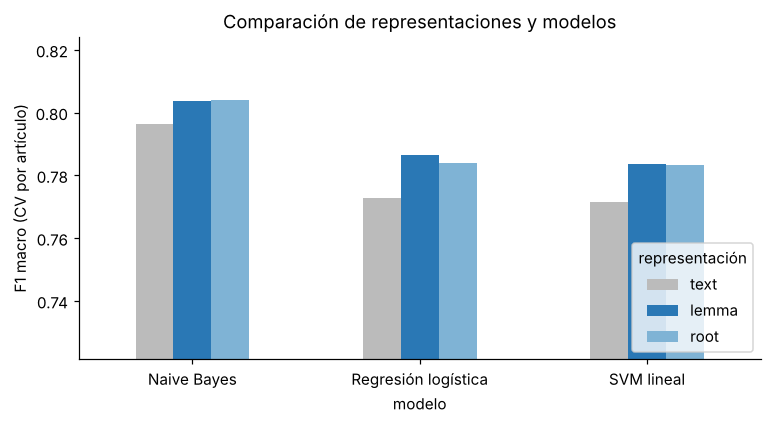

In [18]:
pivot = comparativa.pivot(index="modelo", columns="representación", values="f1_macro")[["text", "lemma", "root"]]
ax = pivot.plot.bar(figsize=(8, 3.8), rot=0, color=["#bbb", "#2a78b5", "#7fb3d5"])
ax.set_ylim(pivot.values.min() - 0.05, pivot.values.max() + 0.02)
ax.set_ylabel("F1 macro (CV por artículo)"); ax.set_title("Comparación de representaciones y modelos")
ax.legend(title="representación", loc="lower right"); plt.show()

#### Ajuste de hiperparámetros

Sobre la mejor representación se ajusta el hiperparámetro principal del mejor
modelo y se prueba si añadir **bigramas** ayuda (p. ej. *nigra truo*, *kemia
reakcio*).

In [19]:
from sklearn.model_selection import GridSearchCV

mejor = comparativa.iloc[0]
REP = mejor["representación"]
X_txt = REPRESENTACIONES[REP]
modelo_base = candidate_models()[mejor["modelo"]]
param = {"Naive Bayes": {"clf__alpha": [0.01, 0.05, 0.1, 0.3, 1.0]},
         "Regresión logística": {"clf__C": [1, 3, 10, 30]},
         "SVM lineal": {"clf__C": [0.1, 0.3, 1, 3]}}[mejor["modelo"]]
param["tfidf__ngram_range"] = [(1, 1), (1, 2)]

busqueda = GridSearchCV(build_pipeline(modelo_base), param, scoring="f1_macro", cv=cv_grupos, n_jobs=-1)
busqueda.fit(X_txt, y, groups=grupos)
print(f"Modelo: {mejor['modelo']} · representación: {REP}")
print("Mejores hiperparámetros:", busqueda.best_params_, f"→ F1 macro CV = {busqueda.best_score_:.3f}")

Modelo: Naive Bayes · representación: root
Mejores hiperparámetros: {'clf__alpha': 0.1, 'tfidf__ngram_range': (1, 2)} → F1 macro CV = 0.809


#### ¿Por qué agrupar por artículo? (fuga de información)

Misma configuración, evaluada con una validación cruzada **aleatoria** por párrafos:

In [20]:
cv_aleatoria = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
f1_aleatoria = cross_validate(busqueda.best_estimator_, X_txt, y, cv=cv_aleatoria,
                              scoring="f1_macro", n_jobs=-1)["test_score"].mean()
print(f"F1 macro con CV aleatoria por párrafo : {f1_aleatoria:.3f}  (optimista)")
print(f"F1 macro con CV agrupada por artículo : {busqueda.best_score_:.3f}  (realista)")

F1 macro con CV aleatoria por párrafo : 0.887  (optimista)
F1 macro con CV agrupada por artículo : 0.809  (realista)


### 3.3 Modelo final: entrenamiento y evaluación en test

In [21]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

# Partición 80/20 por artículo (la primera de las 5 particiones agrupadas ≈ 20 %)
idx_train, idx_test = next(cv_grupos.split(X_txt, y, grupos))
X_train = [X_txt[i] for i in idx_train]; X_test = [X_txt[i] for i in idx_test]
y_train, y_test = y[idx_train], y[idx_test]
print(f"train: {len(idx_train)} párrafos · test: {len(idx_test)} párrafos "
      f"({len(set(grupos[idx_test]))} artículos que el modelo nunca ha visto)")

modelo = clone(busqueda.best_estimator_)
# La SVM no da probabilidades: si gana, se calibra para poder usar predict_proba
if not hasattr(modelo.named_steps["clf"], "predict_proba"):
    modelo.steps[-1] = ("clf", CalibratedClassifierCV(modelo.named_steps["clf"], cv=3))
t0 = time.time()
modelo.fit(X_train, y_train)
print(f"Entrenado en {time.time() - t0:.2f} s")

y_pred = modelo.predict(X_test)
print(f"\nAccuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 macro : {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

train: 4414 párrafos · test: 1104 párrafos (162 artículos que el modelo nunca ha visto)


Entrenado en 0.16 s

Accuracy : 0.854
F1 macro : 0.850

              precision    recall  f1-score   support

    biologio      0.802     0.896     0.846       316
      fiziko      0.895     0.869     0.882       459
       kemio      0.856     0.793     0.823       329

    accuracy                          0.854      1104
   macro avg      0.851     0.853     0.850      1104
weighted avg      0.856     0.854     0.854      1104



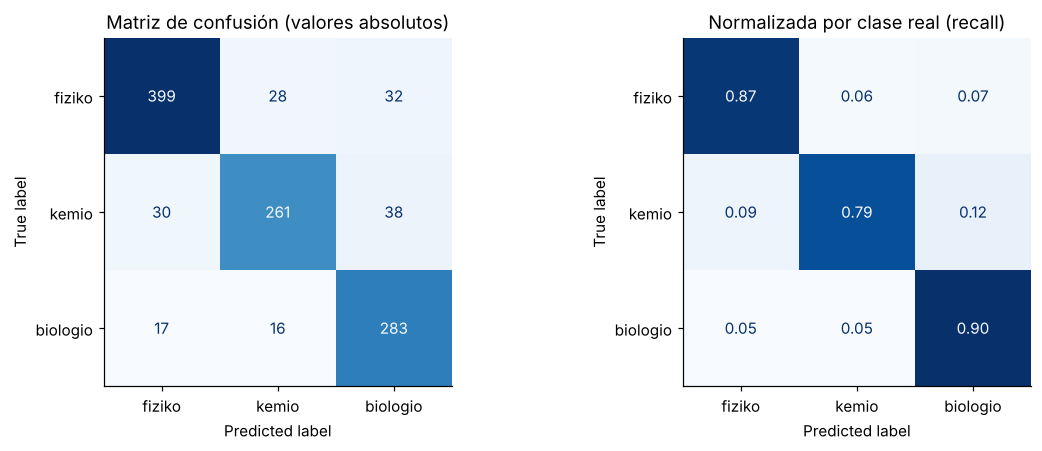

In [22]:
clases = list(CATEGORIES)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=clases), display_labels=clases).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (valores absolutos)")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=clases, normalize="true"),
                       display_labels=clases).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Normalizada por clase real (recall)")
plt.tight_layout(); plt.show()

### 3.4 Interpretación: palabras más discriminantes

Los pesos del modelo lineal muestran qué lemas empujan hacia cada clase. Es una
comprobación de que el modelo ha aprendido vocabulario temático y no artefactos.

In [23]:
modelo_interpretable = clone(busqueda.best_estimator_).fit(X_train, y_train)
top = top_features(modelo_interpretable, n=15)
display(pd.DataFrame(top)[clases])

,fiziko,kemio,biologio
0,fizik,kemi,viv
1,fort,element,hom
2,sistem,molekul,biologi
3,objekt,atom,speci
4,energi,reakci,organism
5,rapid,elektron,masaĝ
6,mekanik,grup,ĉel
7,son,metal,korp
8,korp,substanc,best
9,leĝ,struktur,mort


### 3.5 Medición del ruido de etiquetado con el clasificador

Segunda medida del ruido de la Fase 1: con **predicciones fuera de la partición**
(*out-of-fold*, cada párrafo lo predice un modelo que no ha visto su artículo),
se cuentan los párrafos en los que el modelo **contradice la etiqueta con mucha
seguridad** (probabilidad > 0.8 para otra clase). Son los candidatos a párrafos
genéricos o mal etiquetados.

In [24]:
from sklearn.model_selection import cross_val_predict

modelo_oof = clone(modelo)
proba_oof = cross_val_predict(modelo_oof, X_txt, y, groups=grupos, cv=cv_grupos,
                              method="predict_proba", n_jobs=-1)
clases_oof = np.array(sorted(set(y)))
pred_oof = clases_oof[proba_oof.argmax(1)]
conf_oof = proba_oof.max(1)
df["pred_oof"], df["conf_oof"] = pred_oof, conf_oof
df["ruido_probable"] = (pred_oof != y) & (conf_oof > 0.8)

tabla_ruido = pd.DataFrame({
    "% contradice etiqueta (>0.8)": df.groupby("class")["ruido_probable"].mean() * 100,
    "% sin término de dominio": df.groupby("class")["sin_termino_de_dominio"].mean() * 100,
}).round(1).loc[clases]
display(tabla_ruido)
print(f"Estimación global de ruido (clasificador): {df['ruido_probable'].mean()*100:.1f} % de los párrafos")
print(f"Solo el {df.loc[df['ruido_probable'], 'sin_termino_de_dominio'].mean()*100:.0f} % de esos párrafos "
      "carece de términos de dominio: las dos medidas detectan cosas distintas (ver abajo).")
print("\nEjemplos de párrafos 'ruidosos':")
for _, r in df[df["ruido_probable"]].sample(6, random_state=SEED).iterrows():
    print(f" · etiqueta={r['class']:<8} predicción={r['pred_oof']:<8} ({r['conf_oof']:.2f}) [{r['title']}]")
    print(f"   {r['text'][:170]}")

,% contradice etiqueta (>0.8),% sin término de dominio
class,,
fiziko,5.2,23.3
kemio,8.6,12.1
biologio,3.2,33.6


Estimación global de ruido (clasificador): 5.6 % de los párrafos
Solo el 21 % de esos párrafos carece de términos de dominio: las dos medidas detectan cosas distintas (ver abajo).

Ejemplos de párrafos 'ruidosos':
 · etiqueta=biologio predicción=fiziko   (0.93) [Antropa principo]
   La principo estis reale jam anoncita, sed kun malsama formulado, en 1957, de Robert Dicke. Diversaj kritikistoj trovis teleologiajn spurojn de tiu principo en la filozofi
 · etiqueta=fiziko   predicción=biologio (0.86) [Dando]
   Ne ekzistas “viraj modaĵoj”, kiuj meritas la nomon, post kiam Ludoviko la 16-a de Francio estis gilotinita.
 · etiqueta=fiziko   predicción=biologio (0.96) [Kapacito]
   Pri biologio, eltena kapacito estas la maksimuma loĝantaro de la specio kiun la medio povas daŭrigi senfine.
 · etiqueta=fiziko   predicción=kemio    (0.84) [Kristalo]
   Laŭ Francisko Azorín kristalo estas Mineralo, kiu adoptas poliedran formon. Speco de vitro enhavanta plumbon. Li indikas etimologion el la greka 

La medida heurística (sin términos de dominio) es mucho más alta porque la
lista de raíces es corta: marca como "genérico" cualquier párrafo que use otro
vocabulario. El clasificador es más fino. Al revisar sus ejemplos se ven dos
tipos de "errores":

1. **Ruido real del etiquetado**: párrafos de historia, fechas o biografía que
   no hablan de la ciencia del artículo.
2. **Solapamiento real entre clases**: un párrafo de un artículo de química que
   habla de energía o de luz es, de verdad, de física. Aquí el "error" del
   modelo es razonable.

¿Eliminar estos párrafos? Se ha decidido **no** hacerlo en el conjunto de test
(sería evaluar el modelo con datos elegidos por el propio modelo), pero sí se
comprueba qué pasa si se entrenan sin ellos:

In [25]:
mascara_train_limpio = ~df["ruido_probable"].values[idx_train]
modelo_limpio = clone(modelo).fit([X_train[i] for i in np.where(mascara_train_limpio)[0]],
                                  y_train[mascara_train_limpio])
print(f"F1 macro en test, entrenando con todo        : {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"F1 macro en test, entrenando sin párrafos ruidosos: "
      f"{f1_score(y_test, modelo_limpio.predict(X_test), average='macro'):.3f}")

F1 macro en test, entrenando con todo        : 0.850
F1 macro en test, entrenando sin párrafos ruidosos: 0.852


### 3.6 Modelo final con todos los datos

Para clasificar páginas web se reentrena el modelo con **todo** el dataset
(la evaluación ya se ha hecho con la partición de test).

In [26]:
modelo_final = clone(modelo).fit(X_txt, y)


def clasificar_texto(texto):
    proba = modelo_final.predict_proba([" ".join(doc_to_features(nlp(texto), REP))])[0]
    return {str(c): round(float(p), 3) for c, p in zip(modelo_final.classes_, proba)}


for frase in ["La elektrono havas negativan elektran ŝargon kaj tre malgrandan mason.",
              "Natrio reakcias kun kloro kaj formas natrian kloridon, t.e. kuirsalon.",
              "La fotosintezo okazas en la kloroplastoj de la plantaj ĉeloj."]:
    print(clasificar_texto(frase), "←", frase)

{'biologio': 0.001, 'fiziko': 0.86, 'kemio': 0.139} ← La elektrono havas negativan elektran ŝargon kaj tre malgrandan mason.
{'biologio': 0.007, 'fiziko': 0.003, 'kemio': 0.991} ← Natrio reakcias kun kloro kaj formas natrian kloridon, t.e. kuirsalon.
{'biologio': 0.727, 'fiziko': 0.014, 'kemio': 0.259} ← La fotosintezo okazas en la kloroplastoj de la plantaj ĉeloj.


## 4. Clasificación de páginas web

Se eligen artículos de Vikipedio **que no están en el dataset** (se comprueba
abajo) y se obtienen mediante *web scraping* de la **página HTML** con `requests`
+ `BeautifulSoup` (no con el API): se eliminan `script`, `style`, tablas,
navegación, referencias y cajas de información, y se extraen los párrafos `<p>`,
que se limpian con la misma función que el dataset.

Elegimos una página "fácil" por clase y una **ambigua** a propósito:
*Fotosintezo* (fotosíntesis) es un proceso biológico pero descrito con mucho
vocabulario químico y de energía.

**Robustez**: si una web falla (sin conexión, error HTTP, cambio de formato),
se usa una copia de respaldo publicada en el repositorio; si eso también falla,
esa página se omite con un aviso, pero el cuaderno sigue.

In [27]:
PAGINAS = {
    "https://eo.wikipedia.org/wiki/Nigra_truo": "fiziko",     # agujero negro
    "https://eo.wikipedia.org/wiki/Acido": "kemio",           # ácido
    "https://eo.wikipedia.org/wiki/Mitozo": "biologio",       # mitosis
    "https://eo.wikipedia.org/wiki/Fotosintezo": "biologio",  # fotosíntesis (ambigua)
}
titulos_dataset = set(df["title"])
for url in PAGINAS:
    titulo = requests.utils.unquote(url.rsplit("/", 1)[1]).replace("_", " ")
    print(f"{titulo:<12} ¿está en el dataset? {'SÍ ⚠️' if titulo in titulos_dataset else 'no ✅'}")

respaldo = None


def obtener_parrafos(url):
    global respaldo
    html = fetch_html(url)
    if html:
        parrafos = html_to_paragraphs(html)
        if parrafos:
            return parrafos, "web en vivo"
    if respaldo is None:  # se descarga una sola vez
        try:
            respaldo = requests.get(URL_WEB_SNAPSHOT, timeout=20).json()
        except Exception as exc:
            print(f"  [aviso] tampoco hay copia de respaldo: {type(exc).__name__}")
            respaldo = {}
    return respaldo.get(url, []), "copia de respaldo"

Nigra truo   ¿está en el dataset? no ✅
Acido        ¿está en el dataset? no ✅
Mitozo       ¿está en el dataset? no ✅
Fotosintezo  ¿está en el dataset? no ✅


In [28]:
resultados = []
detalle = {}
for url, esperado in PAGINAS.items():
    parrafos, origen = obtener_parrafos(url)
    nombre = url.rsplit("/", 1)[1].replace("_", " ")
    if not parrafos:
        print(f"[omitida] {nombre}: no se pudo obtener texto")
        continue
    X_web = [" ".join(doc_to_features(d, REP)) for d in nlp.pipe(parrafos)]
    proba_par = modelo_final.predict_proba(X_web)
    proba_pag = proba_par.mean(axis=0)   # probabilidad de la página = media de sus párrafos
    detalle[nombre] = pd.DataFrame(proba_par, columns=modelo_final.classes_).assign(
        texto=[p[:80] + "…" for p in parrafos])
    fila = {"página": nombre, "origen": origen, "párrafos": len(parrafos), "esperada": esperado}
    fila.update({c: p for c, p in zip(modelo_final.classes_, proba_pag)})
    fila["predicción"] = modelo_final.classes_[proba_pag.argmax()]
    resultados.append(fila)

tabla_web = pd.DataFrame(resultados).set_index("página")
display(tabla_web.style.format({c: "{:.1%}" for c in clases})
        .background_gradient(subset=clases, cmap="Greens", axis=1))

  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Nigra_truo: ProxyError


  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Acido: ProxyError
  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Mitozo: ProxyError
  [aviso] no se pudo descargar https://eo.wikipedia.org/wiki/Fotosintezo: ProxyError


,origen,párrafos,esperada,biologio,fiziko,kemio,predicción
página,,,,,,,
Nigra truo,copia de respaldo,36,fiziko,8.9%,87.7%,3.4%,fiziko
Acido,copia de respaldo,52,kemio,12.3%,4.8%,82.8%,kemio
Mitozo,copia de respaldo,5,biologio,80.1%,10.5%,9.3%,biologio
Fotosintezo,copia de respaldo,40,biologio,17.5%,7.7%,74.8%,kemio


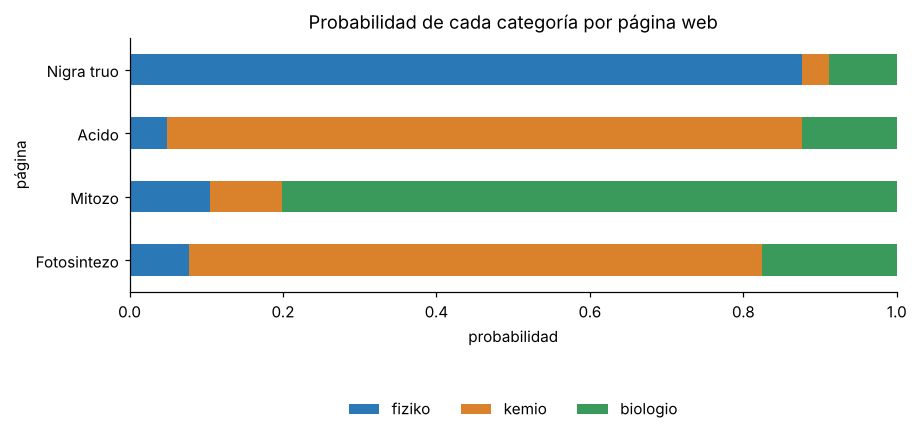

In [29]:
if len(tabla_web):
    ax = tabla_web[clases].plot.barh(stacked=True, figsize=(9, 0.6 + 0.6 * len(tabla_web)),
                                     color=[COLORES[c] for c in clases])
    ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("probabilidad")
    ax.set_title("Probabilidad de cada categoría por página web")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.55), ncol=3, frameon=False)
    plt.show()

**Probabilidad de la página = media de las probabilidades de sus párrafos.**
Se probó también a clasificar la página entera como un único documento, pero
Naive Bayes multiplica la evidencia de miles de palabras y la probabilidad se
satura a 0 % / 100 %, lo que no informa de la mezcla de temas. La media de
párrafos sí lo hace (y el modelo se entrenó precisamente con párrafos).

La clasificación **párrafo a párrafo** de la página ambigua muestra qué partes
tiran hacia cada categoría:

In [30]:
for nombre in list(detalle)[-1:]:   # la página ambigua
    d = detalle[nombre]
    d["predicción"] = d[clases].idxmax(axis=1)
    print(f"{nombre}: reparto de párrafos →", d["predicción"].value_counts().to_dict())
    display(d[["texto"] + clases + ["predicción"]].head(10).style.format({c: "{:.2f}" for c in clases}))

Fotosintezo: reparto de párrafos → {'kemio': 33, 'biologio': 5, 'fiziko': 2}


,texto,fiziko,kemio,biologio,predicción
0,"Fotosintezo estas bioĥemia procezo en plantoj, algoj kaj kelkaj bakterioj, ĉe ki…",0.01,0.81,0.18,kemio
1,La plantoj – en kontrasto al la bestoj – ne kapablas (ankaŭ ne bezonas) sin nutr…,0.00,0.01,0.99,biologio
2,La plantoj konstruas el la neorganikaj kombinaĵoj kiel akvo kaj karbon-dioksido …,0.00,0.99,0.01,kemio
3,La organoj de la fotosintezo estas la verdaj kloroplastoj. En verdaj plantoj kaj…,0.01,0.52,0.47,kemio
4,Kelkaj bakterioj uzas hidrogenan sulfidon anstataŭ akvon dum la fotosintezo:…,0.00,0.98,0.01,kemio
5,"Aliaj elektrondonantoj estas laktoacido kaj izopropanolo, kaj aliaj redukteblaj …",0.20,0.60,0.20,kemio
6,Aliaj procezoj anstataŭigas aliajn kombinaĵojn (ekzemple arseniton) por akvo en …,0.03,0.92,0.05,kemio
7,CO2 + (AsO3) + lumo → (AsO4) + CO (uzata por konstrui aliajn kombinaĵojn en sekv…,0.24,0.73,0.03,kemio
8,Ĉe bestoj okazas tiu ĉi procezo dum la spirado kontraŭe: tie el sukero kaj oksig…,0.07,0.92,0.01,kemio
9,"La fotosintezo havas du ŝtupojn, kiuj estas la lumaj reakcioj (akcepto, transfor…",0.02,0.98,0.00,kemio


## 5. Conclusiones

* **Dataset**: más de 1 500 párrafos por clase obtenidos automáticamente de
  Vikipedio, con un *script* reproducible y tolerante a fallos. El etiquetado
  heredado del artículo introduce ruido, que se ha medido de dos formas
  (vocabulario de dominio y desacuerdo del clasificador).
* **Modelo de NLP**: la regularidad del Esperanto permite un tokenizador,
  lematizador, etiquetador morfológico y gestor de stop-words basado en reglas,
  con un API como el de spaCy (`nlp(texto)` → `Doc` → `Token`), que acierta casi
  todos los tokens del *gold standard*.
* **Clasificación**: las representaciones que usan el modelo de NLP (lema o
  raíz) mejoran ligeramente a la palabra sin procesar y reducen el vocabulario
  casi a la mitad. Naive Bayes es el mejor modelo y consigue un F1 macro de
  ≈0.80 en validación cruzada por artículo y ≈0.85 en el test. La validación
  aleatoria por párrafos daría ≈0.89, una cifra inflada por la fuga de
  información entre párrafos del mismo artículo.
* **Web**: las tres páginas "claras" (*Nigra truo*, *Acido*, *Mitozo*) se
  clasifican correctamente con mucha seguridad. La página ambigua,
  *Fotosintezo*, sale como **química**: la mayoría de sus párrafos describen
  reacciones, moléculas y energía (es, en realidad, bioquímica). Es un resultado
  razonable, que además se explica por una decisión de la Fase 1: se excluyó la
  subcategoría *Biokemio* del dataset, así que el modelo asocia ese vocabulario
  a la química.

**Limitaciones y mejoras posibles**:

* El léxico cerrado no es exhaustivo y las reglas de participios generan algún
  falso positivo (*konstanta*), que se corrige con una lista de excepciones.
* El *gold standard* de la Fase 2 es pequeño (10 frases); un 100 % en él no
  significa que el modelo no se equivoque en textos reales.
* Algunos artículos muy largos pesan demasiado en su clase (p. ej. *masaĝ* entre
  las palabras más discriminantes de biología viene de un único artículo largo).
  Se podría limitar el número de párrafos por artículo.
* El dataset se podría limpiar más eliminando los párrafos genéricos detectados
  en 3.5, aunque en nuestras pruebas apenas cambia el resultado.